# Market Direction Prediction: From Chart-Image CNN to Tabular ML

| | |
|---|---|
| **Type** | Personal machine-learning project |
| **Domain** | Financial time series · Forex (GBPUSD, USDJPY) |
| **Tools** | Python, pandas, NumPy, scikit-learn, LightGBM, XGBoost, Optuna, `ta`, MetaTrader5 API, matplotlib, PyTorch |
| **Date** | 2026 |
| **Repository** | [RenzWoo/market-direction-ml (dummy link)](https://github.com/RenzWoo/market-direction-ml) |

:::{tip} TL;DR
An end-to-end pipeline that pulls raw price bars from MetaTrader 5, engineers technical and candle-shape features, labels each bar by whether price hits an ATR-scaled upper or lower target first, and compares tuned Random Forest, LightGBM, and XGBoost classifiers with time-aware validation. The project started as a **chart-image CNN** and evolved into a tabular approach. The honest outcome: only a **weak signal** (walk-forward CV AUC ≈ 0.55, holdout AUC between 0.47 and 0.59), and the main lesson is about rigorous, leakage-free evaluation.
:::

<div class="stats-grid">
<div class="stat-card"><div class="stat-num">58.6k</div><div class="stat-desc">30-min bars per FX pair (Jan 2022 to Sep 2026)</div></div>
<div class="stat-card"><div class="stat-num">17</div><div class="stat-desc">engineered model features</div></div>
<div class="stat-card"><div class="stat-num">3</div><div class="stat-desc">model families tuned with Bayesian search (Optuna)</div></div>
<div class="stat-card"><div class="stat-num">≈ 0.55</div><div class="stat-desc">tuned walk-forward CV AUC (chance = 0.50)</div></div>
</div>

## 1. Problem Statement

Can simple, interpretable market features predict whether price will move **up, down, or stay neutral** over the
next few hours, and can that signal survive *time-aware* validation?

**Objectives**

- Build a reproducible data pipeline from a broker feed to a model-ready table.
- Define a **label** that reflects a tradable move (volatility-scaled), not just "next candle up/down".
- Identify which features carry signal and which are redundant.
- Tune and compare tree-ensemble models without look-ahead leakage.
- Report results honestly, including when there is little to no edge.

**Project evolution**

| Phase | Idea | What exists in the repo |
|---|---|---|
| 1. Chart-image CNN | Render 30-candle price windows as images labelled `up` / `down` / `neutral` (5-step look-ahead, ±0.3% threshold) and classify them with a CNN | Image-dataset generator (`CNN_model_window.py`) and a PyTorch checkpoint inspector. The CNN training code and image folders are not committed (`dataset/` is git-ignored). |
| 2. Tabular ML | Engineer indicator/candle features and use gradient-boosted trees | Feature pipeline, feature analysis, Optuna tuning, model evaluation notebooks |

## 2. Data & Storage

| Layer | Details |
|---|---|
| **Source** | MetaTrader 5 broker feed via the `MetaTrader5` Python API (`copy_rates_range`, with a fallback to `copy_rates_from_pos` when the date range fails). Timestamps requested in UTC. |
| **Raw fields** | `open, high, low, close, tick_volume (→ volume), real_volume, spread`, indexed by `time` |
| **Volume** | GBPUSD 30-min: **58,615 bars**; USDJPY 30-min: **58,618 bars** (2022-01-03 to 2026-09-18). A 5-minute set hit the broker's ~100k-bar cap (99,999 bars from May 2025); a daily set has 446 bars. |
| **In-memory** | `pandas.DataFrame` with `DatetimeIndex`, sorted chronologically (MT5 exports can arrive newest-first) |
| **On disk** | Feature tables saved as CSV snapshots (e.g. `GBPUSD_M30_2024-2026_final.csv`, `usdjpy_final.csv`); chart images stored in class folders (`up/`, `down/`, `neutral/`); model weights in a `.pth` checkpoint |
| **Repo hygiene** | Large/derived folders (`dataset/`, `dataset_test/`, `literatures/`) excluded with `.gitignore` |

## 3. Preprocessing & Feature Engineering

**Cleaning steps**

- Parse timestamps → `DatetimeIndex`, sort ascending, drop unused `real_volume` (all zeros for FX).
- Check whether volume is populated; only build volume features if it is.
- Replace impossible zeros with `NaN` (`atr`, `adx`) and guard divisions by zero-range bars.
- Drop rows with missing values or labels *after* feature/label construction (warm-up rows for rolling indicators and the tail rows that have no future).
- Apply a **late-session filter** (`hour > 19`) to the 30-minute FX datasets.
- Chronological **train/test split**: the last 1,000 rows are a holdout; nothing is shuffled.
- Wrap models in scikit-learn `Pipeline`s (`SimpleImputer` → Random Forest) so preprocessing is fitted on training data only.

**Engineered features (17)**

| Group | Features |
|---|---|
| Volatility | `atr` (14), `atr_daily` (window ≈ one trading day), `atr_ratio` (bar range ÷ ATR) |
| Momentum / trend | `rsi` (14), `roc` (10), `adx` (14), `cci` (20) |
| Candle shape (scale-free) | `bar_direction`, `close_position`, `body_ratio`, `upper_wick`, `lower_wick` |
| Participation | `volume`, `rel_volume` (volume ÷ 20-bar mean), `spread` |
| Time | `hour`, `dayofweek` |

Raw price levels (`open/high/low/close`) are **deliberately excluded** from the model inputs because they are
non-stationary.

**Label design (triple-barrier style)**

```text
threshold   = ATR_daily[t-1] × multiplier          # volatility-scaled; ATR lagged 1 bar to avoid leakage
upper / lower barriers = close[t] ± threshold
label = 1 (UP)      if a future HIGH touches the upper barrier first within the look-ahead window
        0 (DOWN)    if a future LOW touches the lower barrier first
        2 (NEUTRAL) if neither is touched
```

Resulting label balance after filtering (GBPUSD 30-min, 9,725 rows): **4,246 down, 4,186 up, 1,293 neutral.**

## 4. Method

```text
MT5 feed ─▶ bars (DataFrame) ─▶ indicators + candle features ─▶ barrier labels ─▶ dropna + session filter
        ─▶ feature selection (F-test · mutual information · RF importance · correlation)
        ─▶ Optuna tuning with walk-forward CV (TimeSeriesSplit, 5 folds)
        ─▶ chronological holdout evaluation (last 1,000 rows)
```

**Feature selection** (GBPUSD 30-min sample, 31,910 rows, 16 candidate features) combined four views:
ANOVA F-test (linear signal), mutual information (non-linear), Random-Forest importance (time-ordered fit),
and a Pearson correlation check for redundancy (|r| > 0.8).

**Hyperparameter tuning**

- Optuna (Bayesian optimisation), maximising **macro one-vs-rest ROC-AUC** averaged over 5 `TimeSeriesSplit` folds.
- Search spaces: Random Forest (11 parameters incl. `ccp_alpha`, `class_weight`, `max_samples`), LightGBM
  (regularisation, leaves, learning rate) and XGBoost (depth, `gamma`, L1/L2).
- A custom **early-stopping callback** (patience 50 trials, min improvement 0.001) ends stagnant studies.
- Folds where a class is missing return `NaN` and are ignored rather than crashing the search.

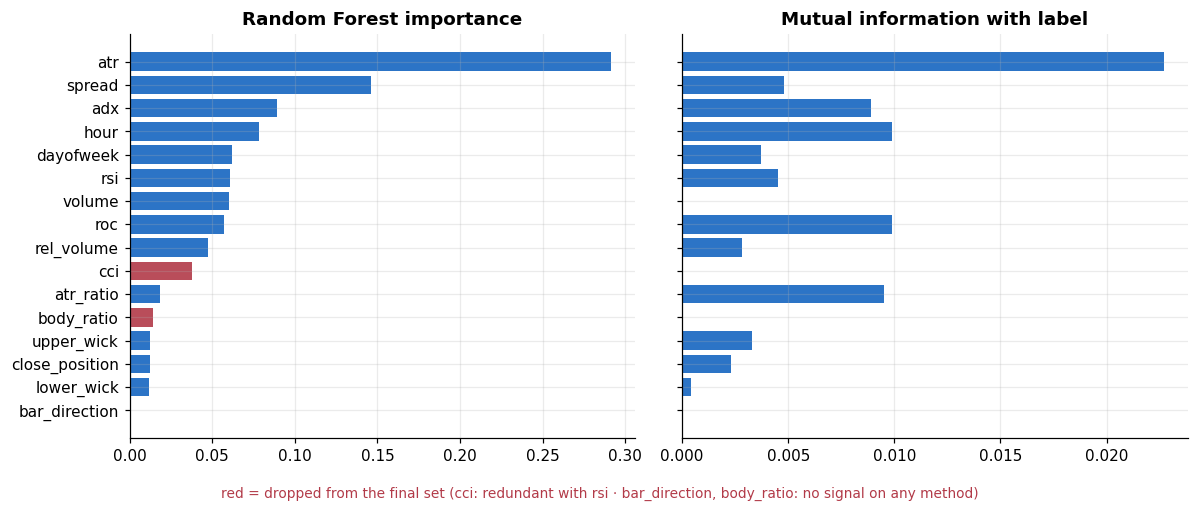

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NAVY, BLUE, SKY, GOLD, RED, GREY = "#0A2540", "#1565C0", "#4FC3F7", "#E0A030", "#B23A48", "#8A94A6"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10,
})

# Transcribed from the saved Feature-analysis notebook output (GBPUSD 30-min, n = 31,910)
fa = pd.DataFrame({
    "feature": ["atr","spread","adx","hour","dayofweek","rsi","volume","roc","rel_volume","cci",
                "atr_ratio","body_ratio","upper_wick","close_position","lower_wick","bar_direction"],
    "rf_importance": [0.2915,0.1462,0.0893,0.0786,0.0619,0.0605,0.0599,0.0572,0.0477,0.0376,
                      0.0185,0.0139,0.0124,0.0121,0.0120,0.0006],
    "mutual_info":   [0.0227,0.0048,0.0089,0.0099,0.0037,0.0045,0.0000,0.0099,0.0028,0.0000,
                      0.0095,0.0000,0.0033,0.0023,0.0004,0.0000],
})
dropped = {"cci": "redundant with RSI (r = 0.84)", "bar_direction": "no signal", "body_ratio": "no signal"}

fa = fa.sort_values("rf_importance")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
colors = [RED if f in dropped else BLUE for f in fa.feature]
axes[0].barh(fa.feature, fa.rf_importance, color=colors, alpha=0.9)
axes[0].set_title("Random Forest importance")
axes[1].barh(fa.feature, fa.mutual_info, color=colors, alpha=0.9)
axes[1].set_title("Mutual information with label")
fig.text(0.5, 0.005, "red = dropped from the final set (cci: redundant with rsi · bar_direction, body_ratio: no signal on any method)",
         fontsize=9, color=RED, ha="center")
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

**Feature-selection findings**

- **Volatility dominates.** `atr` ranks first under all three methods, and `spread` and time-of-day
  (`hour`) also rank high on several of them. This makes sense: the label is defined by ATR-scaled barriers, so volatility regimes shape it.
- `rsi` and `cci` are highly correlated (r = 0.84), so the weaker one (`cci`) was dropped. `bar_direction` and
  `body_ratio` showed no measurable signal on any method. **13 features** were recommended.
- Several features are statistically significant by F-test yet carry very little mutual information, a
  reminder that a small p-value on 30k rows is not the same as predictive usefulness.

## 5. Results

### 5.1 Tuning (walk-forward CV, macro OvR AUC)

| Feature set | Random Forest | LightGBM | XGBoost |
|---|---|---|---|
| All 16 candidates | 0.5481 | 0.5481 | 0.5487 |
| 13-feature subset | 0.5483 | **0.5504** | 0.5485 |
| 14-feature subset | 0.5475 | 0.5496 | **0.5500** |

All three model families converged on **≈ 0.55**, and re-running with different feature subsets barely moved
the score. The ceiling comes from the **features and label**, not from the choice of algorithm.

### 5.2 Chronological holdout (last 1,000 rows)

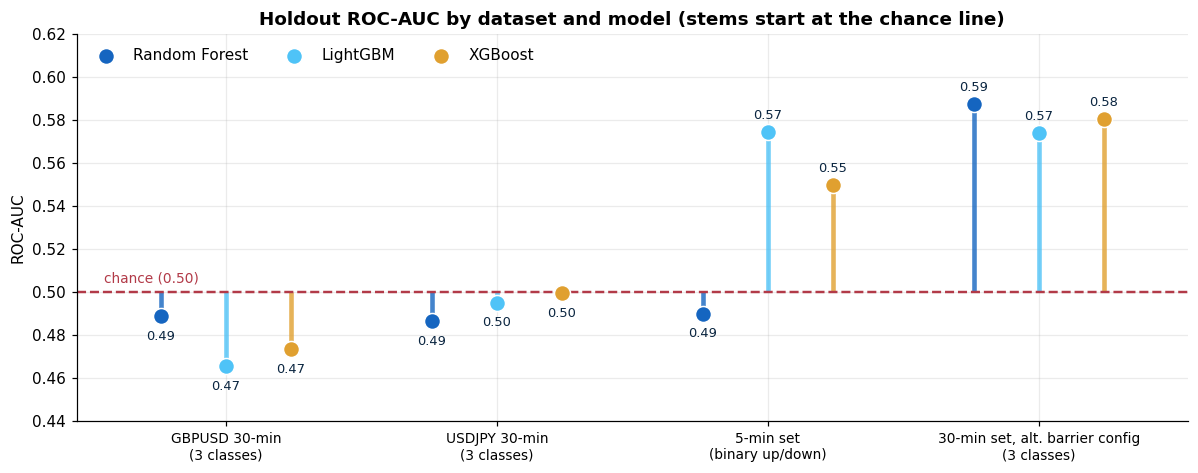

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NAVY, BLUE, SKY, GOLD, RED, GREY = "#0A2540", "#1565C0", "#4FC3F7", "#E0A030", "#B23A48", "#8A94A6"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10,
})

# Holdout ROC-AUC (macro OvR) transcribed from the saved evaluation output
hold = pd.DataFrame({
    "GBPUSD 30-min\n(3 classes)":            [0.4887, 0.4657, 0.4735],
    "USDJPY 30-min\n(3 classes)":            [0.4866, 0.4951, 0.4994],
    "5-min set\n(binary up/down)":           [0.4900, 0.5745, 0.5497],
    "30-min set, alt. barrier config\n(3 classes)": [0.5874, 0.5742, 0.5806],
}, index=["Random Forest", "LightGBM", "XGBoost"])

x = np.arange(hold.shape[1]); w = 0.24
fig, ax = plt.subplots(figsize=(11, 4.4))
for i, (model, color) in enumerate(zip(hold.index, [BLUE, SKY, GOLD])):
    xs = x + (i - 1) * w
    vals = hold.loc[model].values
    ax.vlines(xs, 0.5, vals, color=color, lw=3, alpha=0.8)          # stem from the chance line
    ax.scatter(xs, vals, s=110, color=color, zorder=3, label=model, edgecolor="white", linewidth=1)
    for xv, v in zip(xs, vals):
        ax.text(xv, v + (0.006 if v >= 0.5 else -0.011), f"{v:.2f}", ha="center", fontsize=8.5, color=NAVY)
ax.axhline(0.5, color=RED, ls="--", lw=1.6)
ax.text(-0.45, 0.5045, "chance (0.50)", color=RED, fontsize=9, ha="left")
ax.set_xticks(x); ax.set_xticklabels(hold.columns, fontsize=9)
ax.set_xlim(-0.55, len(x) - 0.45); ax.set_ylim(0.44, 0.62); ax.set_ylabel("ROC-AUC")
ax.set_title("Holdout ROC-AUC by dataset and model (stems start at the chance line)")
ax.legend(ncol=3, loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

**How to read this**

- On the two main 30-minute FX datasets, holdout AUC sits **at or below 0.50**: no reliable edge.
- The higher values (0.57–0.59) come from alternative labelling configurations evaluated on only 1,000 rows
  (a few weeks of bars). After trying many dataset/label/model combinations, some scores above chance are
  expected from **selection noise alone**, so they are treated as leads, not findings.
- The gap between CV (≈ 0.55) and holdout (≈ 0.50) suggests optimistic validation: label windows overlap
  across folds, and hyperparameters were selected on the same folds. It may also reflect regime change.
- Macro-F1 stays low (≈ 0.24–0.32 on the three-class sets), consistent with little usable signal.

## 6. Data Science Concepts Demonstrated

| Concept | Where it appears |
|---|---|
| **Data ingestion from an API** | MetaTrader 5 client with fallback logic and UTC handling |
| **Time-series feature engineering** | Rolling indicators (ATR, RSI, ADX, ROC, CCI), relative volume, candle geometry, calendar features |
| **Label engineering** | Volatility-scaled triple-barrier labels; lagged ATR to prevent target leakage |
| **Stationarity awareness** | Raw price levels excluded; scale-free ratios used |
| **Feature selection** | ANOVA F-test, mutual information, RF importance, correlation-based redundancy pruning |
| **Leakage-safe validation** | Chronological split, `TimeSeriesSplit`, preprocessing inside the `Pipeline` |
| **Hyperparameter optimisation** | Optuna Bayesian search with custom early stopping |
| **Multiclass evaluation** | Macro one-vs-rest ROC-AUC, F1, log-loss, per-class fallbacks |
| **Class imbalance handling** | `class_weight` options in the search space; neutral class is the minority |
| **Honest reporting** | Comparison against chance level; noise and selection-bias caveats |
| **Computer vision (exploratory)** | Chart-image dataset generation for a CNN |

## 7. Limitations & Next Steps

- **Purged / embargoed cross-validation.** Labels look up to ~47 bars ahead, so neighbouring samples overlap.
  Use purged walk-forward CV to remove that leakage before trusting tuned scores.
- **Same-bar ambiguity.** If a bar touches both barriers, the label currently checks the upper barrier first;
  finer-timeframe data or a tie rule would remove this bias.
- **Larger, multi-window holdout.** Replace the single 1,000-row test with rolling out-of-sample windows and
  report mean ± SD; correct for the number of configurations tried.
- **Trading realism.** Add spreads, slippage, and a simple backtest (Sharpe, drawdown) to test whether even a
  small AUC is exploitable.
- **Probability calibration and thresholds.** Calibrate probabilities and abstain on low-confidence bars.
- **Revisit the CNN.** Finish the image branch (train and evaluate, then compare against the tabular baseline).
- **Experiment tracking.** Log runs with MLflow or Weights & Biases and package the pipeline as a script or CLI.